##### Citation Info
@InProceedings{Gushchin_2026_CVPR,
    author    = {Gushchin, Aleksandr and Abud, Khaled and Shumitskaya, Ekaterina and Filippov, Artem and Bychkov, Georgii and Lavrushkin, Sergey and Erofeev, Mikhail and Antsiferova, Anastasia and Chen, Changsheng and Tan, Shunquan and Timofte, Radu and Vatolin, Dmitriy and Song, Chuanbiao and Yu, Zijian and Tan, Hao and Lan, Jun and Yang, Zhiqiang and Tang, Yongwei and Wu, Zhiqiang and Seow, Jia Wen and Koay, Hong Vin and Ren, Haodong and Xu, Feng and Chen, Shuai and Xia, Ruiyang and Zhang, Qi and Xu, Yaowen and Zou, Zhaofan and Sun, Hao and Lu, Dagong and Yao, Mufeng and Xu, Xinlei and Wu, Fei and Guo, Fengjun and Luo, Cong and Sharma, Hardik and Negi, Aashish and Shaily, Prateek and Kumar, Jayant and Chaudhary, Sachin and Dudhane, Akshay and Hambarde, Praful and Shukla, Amit and Tu, Zhilin and Li, Fengpeng and Zhang, Jiamin and Fei, Jianwei and Li, Kemou and Wu, Haiwei and Benjdira, Bilel and Ali, Anas M. and Boulila, Wadii and Qu, Chenfan and Li, Junchi},
    title     = {NTIRE 2026 Challenge on Robust AI-Generated Image Detection in the Wild},
    booktitle = {Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR) Workshops},
    month     = {June},
    year      = {2026},
    pages     = {1895-1913}
}


In [1]:
import torch
import torchvision

# check NVIDIA GPU available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [2]:
# Set up image transforms, datasets, and data loaders

from torch.utils.data import DataLoader
from torchvision.models import ResNet50_Weights
from torchvision import transforms
from torchvision.transforms import v2
from image_distortions import RandomDownscale
from aigendet_dataset import AIGenDetDataset

# Evaluation remains deterministic and uses the pretrained weights' preprocessing.
transform = ResNet50_Weights.DEFAULT.transforms()

# Apply distortions randomly and independently
distortions = v2.Compose([
    v2.ToImage(),
    v2.RandomApply([
        v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    ], p=0.30),
    v2.RandomApply([
        v2.GaussianBlur(kernel_size=5, sigma=(0.1, 1.2)),
    ], p=0.25),
    v2.RandomApply([
        v2.GaussianNoise(mean=0.0, sigma=0.015, clip=True),
    ], p=0.15),
    v2.RandomApply([
        RandomDownscale(scale_min=0.35, scale_max=0.9),
    ], p=0.50),
    v2.RandomApply([
        v2.JPEG(quality=(40, 95)),
    ], p=0.70),
    v2.ToPILImage(),
])

# Resize and normalize images, then apply distortions to half of training set.
train_transform = transforms.Compose([
    transforms.Resize(
        transform.resize_size, interpolation=transform.interpolation,
        antialias=transform.antialias,
    ),
    v2.RandomApply([distortions], p=0.50),
    transform,
])

batch_size = 32

train_path = "../data/train"
train_shard_nums = [0, 5] # list of training shards to use (0-5)
train = AIGenDetDataset(train_path, train_shard_nums, transform=train_transform)
val = AIGenDetDataset(
    image_dir="../data/val/val/val_images",
    labels_csv="../data/val/val/val_labels.csv",
    transform=transform,
)
val_hard = AIGenDetDataset(
    image_dir="../data/val/val_hard/val_images_hard",
    labels_csv="../data/val/val_hard/val_hard_labels.csv",
    transform=transform,
)
test = AIGenDetDataset(
    image_dir="../data/test/test_images",
    labels_csv="../data/test/test_labels.csv",
    transform=transform,
)

trainloader = DataLoader(train, batch_size=batch_size, shuffle=True, num_workers=8, pin_memory=True, persistent_workers=True)
valloader = DataLoader(val, batch_size=batch_size, shuffle=False, num_workers=8, pin_memory=True, persistent_workers=True)
val_hardloader = DataLoader(val_hard, batch_size=batch_size, shuffle=False, num_workers=8, pin_memory=True, persistent_workers=True)

# Creating this loader does not run test evaluation.
testloader = DataLoader(test, batch_size=batch_size, shuffle=False, num_workers=8, pin_memory=True, persistent_workers=True)


Found 2 shards, 77643 images in total.
Found 10000 images in ../data/val/val/val_images.
Found 2500 images in ../data/val/val_hard/val_images_hard.
Found 2500 images in ../data/test/test_images.


In [3]:
# Set up model for fine tuning

import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

model = resnet50(weights=ResNet50_Weights.DEFAULT)

# Replace the final layer with a new one that has 2 output classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 2)

for name, parameter in model.named_parameters():
    parameter.requires_grad = name.startswith(
        ("layer3.", "layer4.", "fc.")
    )

model.to(device)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [4]:
# set up optimizer

import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam([
    {"params": model.layer3.parameters(), "lr": 1e-5},
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4},
])

In [5]:
# Train/eval loop
from sklearn.metrics import roc_auc_score

best_roc_auc = float('-inf')
miss_count = 0
max_misses = 5

for epoch in range(50):
    model.train()
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    running_loss = 0.0

    for i, batch in enumerate(trainloader, 0):
        images = batch["image"].to(device)
        binary_labels = batch["label"].to(device)
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, binary_labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 250 == 249:    # print every 250 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 250:.6f}')
            running_loss = 0.0
    print(f'Finished epoch {epoch + 1}')
    
    # Validation
    model.eval()
    y_true, y_ai_probability = [], []

    with torch.no_grad():
        for batch in valloader:
            images = batch["image"].to(device)
            ai_probability = model(images).softmax(dim=1)[:, 1]

            y_true.extend(batch["label"].tolist())
            y_ai_probability.extend(ai_probability.cpu().tolist())

    val_roc_auc = roc_auc_score(y_true, y_ai_probability)
    print(f"Validation ROC AUC: {val_roc_auc:.6f}")

    if val_roc_auc > best_roc_auc:
        best_roc_auc = val_roc_auc
        miss_count = 0
        torch.save(model, "../models/ResNet50FineTuned_multidistortions.pth")
    else:
        miss_count += 1
        if miss_count >= max_misses:
            print("ROC AUC stopped improving, stopping early.")
            break

print('Finished Training')

[1,   250] loss: 0.491277
[1,   500] loss: 0.336162
[1,   750] loss: 0.311180
[1,  1000] loss: 0.270528
[1,  1250] loss: 0.269487
[1,  1500] loss: 0.262754
[1,  1750] loss: 0.251657
[1,  2000] loss: 0.250802
[1,  2250] loss: 0.246047
Finished epoch 1
Validation ROC AUC: 0.895634
[2,   250] loss: 0.210014
[2,   500] loss: 0.206402
[2,   750] loss: 0.205057
[2,  1000] loss: 0.198915
[2,  1250] loss: 0.194416
[2,  1500] loss: 0.197975
[2,  1750] loss: 0.186117
[2,  2000] loss: 0.178665
[2,  2250] loss: 0.188951
Finished epoch 2
Validation ROC AUC: 0.897330
[3,   250] loss: 0.153893
[3,   500] loss: 0.152022
[3,   750] loss: 0.161559
[3,  1000] loss: 0.151475
[3,  1250] loss: 0.160460
[3,  1500] loss: 0.160589
[3,  1750] loss: 0.151813
[3,  2000] loss: 0.145495
[3,  2250] loss: 0.149299
Finished epoch 3
Validation ROC AUC: 0.915605
[4,   250] loss: 0.118384
[4,   500] loss: 0.118534
[4,   750] loss: 0.120876
[4,  1000] loss: 0.115986
[4,  1250] loss: 0.114146
[4,  1500] loss: 0.118861
[4, 


Overall: 10000 images
              precision    recall  f1-score   support

        Real      0.835     0.846     0.840      5000
AI-generated      0.844     0.832     0.838      5000

    accuracy                          0.839     10000
   macro avg      0.839     0.839     0.839     10000
weighted avg      0.839     0.839     0.839     10000

Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):
[[4231  769]
 [ 839 4161]]
Balanced accuracy: 0.8392
Brier score (lower is better): 0.1304
Log loss (lower is better): 0.6010
ROC-AUC (higher is better): 0.922229

Clean: 5000 images
              precision    recall  f1-score   support

        Real      0.894     0.846     0.870      2500
AI-generated      0.854     0.900     0.877      2500

    accuracy                          0.873      5000
   macro avg      0.874     0.873     0.873      5000
weighted avg      0.874     0.873     0.873      5000

Confusion matrix (rows: actual, columns: predicted; order: R

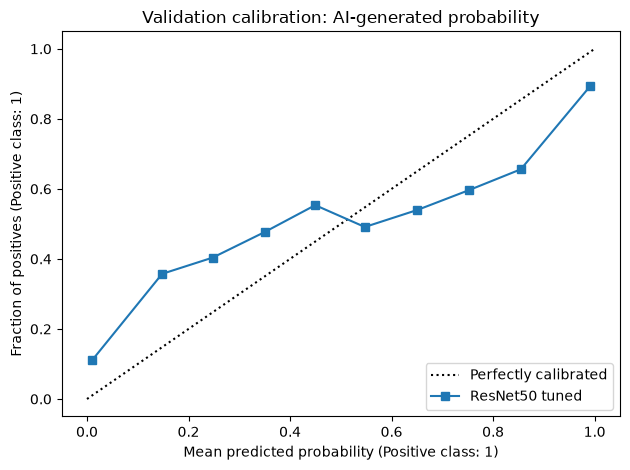

In [6]:
# Get detailed metrics for the current model on the validation set
model = torch.load('../models/ResNet50FineTuned_multidistortions.pth', map_location=device, weights_only=False)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

y_true, y_pred, y_ai_probability, is_distorted = [], [], [], []

model.eval()
with torch.no_grad():
    for batch in valloader:
        images = batch["image"].to(device)
        outputs = model(images)
        probabilities = outputs.softmax(dim=1)
        predictions = probabilities.argmax(dim=1)

        y_true.extend(batch["label"].to(device).tolist())
        y_pred.extend(predictions.tolist())
        # Class 1 is AI-generated; use its probability for every image.
        y_ai_probability.extend(probabilities[:, 1].tolist())
        is_distorted.extend(batch["is_distorted"].tolist())

# Keep the labels, predictions, scores, and distortion flags aligned.
y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_ai_probability = np.asarray(y_ai_probability)
is_distorted = np.asarray(is_distorted)

# Classification uses the existing argmax decision (equivalent to threshold 0.5,
# with ties assigned to Real). ROC AUC uses continuous AI probabilities.
for subset_name, mask in [
    ("Overall", np.ones(len(y_true), dtype=bool)),
    ("Clean", is_distorted == 0),
    ("Distorted (robustness)", is_distorted == 1),
]:
    print(f"\n{subset_name}: {mask.sum()} images")
    if not mask.any():
        print("No images in this subset; skipping metrics.")
        continue

    labels = y_true[mask]
    predicted = y_pred[mask]
    scores = y_ai_probability[mask]
    print(classification_report(
        labels,
        predicted,
        labels=[0, 1],
        target_names=["Real", "AI-generated"],
        digits=3,
        zero_division=0,
    ))
    print("Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):")
    print(confusion_matrix(labels, predicted, labels=[0, 1]))
    print(f"Balanced accuracy: {balanced_accuracy_score(labels, predicted):.4f}")
    print(f"Brier score (lower is better): {brier_score_loss(labels, scores):.4f}")
    print(f"Log loss (lower is better): {log_loss(labels, scores, labels=[0, 1]):.4f}")
    if len(np.unique(labels)) == 2:
        print(f"ROC-AUC (higher is better): {roc_auc_score(labels, scores):.6f}")
    else:
        print("ROC-AUC is undefined: this subset contains only one class.")

# Near the diagonal means predicted AI probabilities match observed AI frequencies.
CalibrationDisplay.from_predictions(
    y_true,
    y_ai_probability,
    n_bins=10,
    strategy="uniform",
    name="ResNet50 tuned",
)
plt.title("Validation calibration: AI-generated probability")
plt.tight_layout()
plt.show()



Overall: 2500 images
              precision    recall  f1-score   support

        Real      0.691     0.784     0.734      1250
AI-generated      0.750     0.649     0.696      1250

    accuracy                          0.716      2500
   macro avg      0.720     0.716     0.715      2500
weighted avg      0.720     0.716     0.715      2500

Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):
[[980 270]
 [439 811]]
Balanced accuracy: 0.7164
Brier score (lower is better): 0.2428
Log loss (lower is better): 1.2900
ROC-AUC (higher is better): 0.792256

Clean: 1250 images
              precision    recall  f1-score   support

        Real      0.786     0.750     0.768       625
AI-generated      0.761     0.795     0.778       625

    accuracy                          0.773      1250
   macro avg      0.773     0.773     0.773      1250
weighted avg      0.773     0.773     0.773      1250

Confusion matrix (rows: actual, columns: predicted; order: Real, 

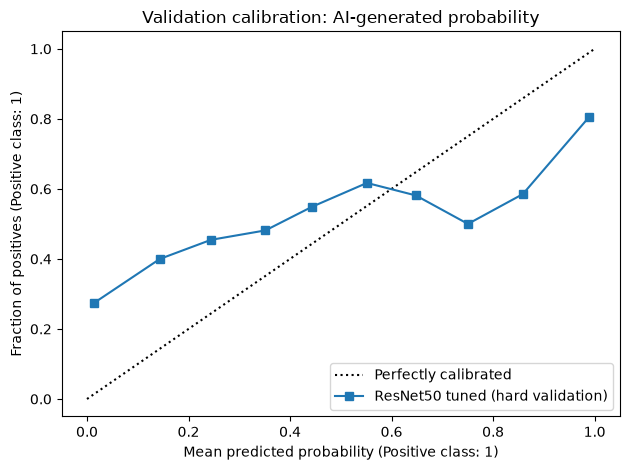

In [7]:
# Get detailed metrics for the current model on the hard validation set
model = torch.load('../models/ResNet50FineTuned_multidistortions.pth', map_location=device, weights_only=False)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

y_true, y_pred, y_ai_probability, is_distorted = [], [], [], []

model.eval()
with torch.no_grad():
    for batch in val_hardloader:
        images = batch["image"].to(device)
        outputs = model(images)
        probabilities = outputs.softmax(dim=1)
        predictions = probabilities.argmax(dim=1)

        y_true.extend(batch["label"].to(device).tolist())
        y_pred.extend(predictions.tolist())
        # Class 1 is AI-generated; use its probability for every image.
        y_ai_probability.extend(probabilities[:, 1].tolist())
        is_distorted.extend(batch["is_distorted"].tolist())

# Keep the labels, predictions, scores, and distortion flags aligned.
y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_ai_probability = np.asarray(y_ai_probability)
is_distorted = np.asarray(is_distorted)

# Classification uses the existing argmax decision (equivalent to threshold 0.5,
# with ties assigned to Real). ROC AUC uses continuous AI probabilities.
for subset_name, mask in [
    ("Overall", np.ones(len(y_true), dtype=bool)),
    ("Clean", is_distorted == 0),
    ("Distorted (robustness)", is_distorted == 1),
]:
    print(f"\n{subset_name}: {mask.sum()} images")
    if not mask.any():
        print("No images in this subset; skipping metrics.")
        continue

    labels = y_true[mask]
    predicted = y_pred[mask]
    scores = y_ai_probability[mask]
    print(classification_report(
        labels,
        predicted,
        labels=[0, 1],
        target_names=["Real", "AI-generated"],
        digits=3,
        zero_division=0,
    ))
    print("Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):")
    print(confusion_matrix(labels, predicted, labels=[0, 1]))
    print(f"Balanced accuracy: {balanced_accuracy_score(labels, predicted):.4f}")
    print(f"Brier score (lower is better): {brier_score_loss(labels, scores):.4f}")
    print(f"Log loss (lower is better): {log_loss(labels, scores, labels=[0, 1]):.4f}")
    if len(np.unique(labels)) == 2:
        print(f"ROC-AUC (higher is better): {roc_auc_score(labels, scores):.6f}")
    else:
        print("ROC-AUC is undefined: this subset contains only one class.")

# Near the diagonal means predicted AI probabilities match observed AI frequencies.
CalibrationDisplay.from_predictions(
    y_true,
    y_ai_probability,
    n_bins=10,
    strategy="uniform",
    name="ResNet50 tuned (hard validation)",
)
plt.title("Validation calibration: AI-generated probability")
plt.tight_layout()
plt.show()
